In [1]:
import pandas as pd
import glob
import numpy as np
import matplotlib.pyplot as plt

## Cleaning the DF's
Currently, we have 6 data frames across various years; we want to combine each of the data frames into one large data frame. Before that we have to do conversions on the "Date" columns and also add new
columns to see if Atletico-MG won or lost.



In [2]:
#Read all of the CSV's in data and make combine into one large DF for easier analysis
csv_files = glob.glob("data/*[0-9][0-9]-[0-9][0-9].csv")
dfs = []
for file in csv_files:
    season = file.replace(".csv", "").replace("data\\", "")
    df_temp = pd.read_csv(file)
    df_temp["Season"] = season
    dfs.append(df_temp)    


In [3]:
df = pd.concat(dfs)

In [4]:
df.head()

,Date,Home Team,Away Team,Score,Time,Competition,Season
0,"Mon, Jan 11",Red Bull Bragantino,Atlético-MG,2 - 2,FT,Brazilian Serie A,2020-21
1,"Mon, Nov 2",Palmeiras,Atlético-MG,3 - 0,FT,Brazilian Serie A,2020-21
2,"Mon, Oct 19",Bahia,Atlético-MG,3 - 1,FT,Brazilian Serie A,2020-21
3,"Sat, Aug 22",Internacional,Atlético-MG,1 - 0,FT,Brazilian Serie A,2020-21
4,"Sat, Dec 12",Athletico Paranaense,Atlético-MG,0 - 1,FT,Brazilian Serie A,2020-21


In [5]:
df.tail()

,Date,Home Team,Away Team,Score,Time,Competition,Season
68,"Wed, Nov 5",Atlético-MG,Bahia,3 - 0,FT,Brazilian Serie A,2025-26
69,"Wed, Oct 15",Atlético-MG,Cruzeiro,1 - 1,FT,Brazilian Serie A,2025-26
70,"Wed, Oct 8",Atlético-MG,Sport,3 - 1,FT,Brazilian Serie A,2025-26
71,"Wed, Sep 17",Bolívar,Atlético-MG,2 - 2,FT,CONMEBOL Sudamericana,2025-26
72,"Wed, Sep 24",Atlético-MG,Bolívar,1 - 0,FT,CONMEBOL Sudamericana,2025-26


In [6]:
#Rename columns for consistancy 
df.columns = [
    "Date",
    "HomeTeam",
    "AwayTeam",
    "Score",
    "Status",
    "Competition",
    "Season"
]

In [7]:
#Extarct numerical values for the away and home goals. Used for training later
df["HomeGoals"] = pd.to_numeric(df["Score"].str[0])
df["AwayGoals"] = pd.to_numeric(df["Score"].str[-1])

In [8]:
df.head()

,Date,HomeTeam,AwayTeam,Score,Status,Competition,Season,HomeGoals,AwayGoals
0,"Mon, Jan 11",Red Bull Bragantino,Atlético-MG,2 - 2,FT,Brazilian Serie A,2020-21,2,2
1,"Mon, Nov 2",Palmeiras,Atlético-MG,3 - 0,FT,Brazilian Serie A,2020-21,3,0
2,"Mon, Oct 19",Bahia,Atlético-MG,3 - 1,FT,Brazilian Serie A,2020-21,3,1
3,"Sat, Aug 22",Internacional,Atlético-MG,1 - 0,FT,Brazilian Serie A,2020-21,1,0
4,"Sat, Dec 12",Athletico Paranaense,Atlético-MG,0 - 1,FT,Brazilian Serie A,2020-21,0,1


In [9]:
df.info()

<class 'pandas.DataFrame'>
Index: 410 entries, 0 to 72
Data columns (total 9 columns):
 #   Column       Non-Null Count  Dtype
---  ------       --------------  -----
 0   Date         410 non-null    str  
 1   HomeTeam     410 non-null    str  
 2   AwayTeam     410 non-null    str  
 3   Score        410 non-null    str  
 4   Status       410 non-null    str  
 5   Competition  410 non-null    str  
 6   Season       410 non-null    str  
 7   HomeGoals    410 non-null    int64
 8   AwayGoals    410 non-null    int64
dtypes: int64(2), str(7)
memory usage: 58.9 KB


In [10]:
#Create a column that says whether Galo (nickname for Atletico-MG) was at home or not. 
df["IsHome"] = (df["HomeTeam"].str.contains("Atlético-MG"))

In [11]:
df.head(10)

,Date,HomeTeam,AwayTeam,Score,Status,Competition,Season,HomeGoals,AwayGoals,IsHome
0,"Mon, Jan 11",Red Bull Bragantino,Atlético-MG,2 - 2,FT,Brazilian Serie A,2020-21,2,2,False
1,"Mon, Nov 2",Palmeiras,Atlético-MG,3 - 0,FT,Brazilian Serie A,2020-21,3,0,False
2,"Mon, Oct 19",Bahia,Atlético-MG,3 - 1,FT,Brazilian Serie A,2020-21,3,1,False
3,"Sat, Aug 22",Internacional,Atlético-MG,1 - 0,FT,Brazilian Serie A,2020-21,1,0,False
4,"Sat, Dec 12",Athletico Paranaense,Atlético-MG,0 - 1,FT,Brazilian Serie A,2020-21,0,1,False
5,"Sat, Dec 26",Atlético-MG,Coritiba,2 - 0,FT,Brazilian Serie A,2020-21,2,0,True
6,"Sat, Feb 13",Atlético-MG,Bahia,1 - 1,FT,Brazilian Serie A,2020-21,1,1,True
7,"Sat, Jan 23",Vasco da Gama,Atlético-MG,3 - 2,FT,Brazilian Serie A,2020-21,3,2,False
8,"Sat, Mar 14",Villa Nova-MG,Atlético-MG,1 - 3,FT,Brazilian Campeonato Mineiro,2020-21,1,3,False
9,"Sat, Mar 7",Atlético-MG,Cruzeiro,2 - 1,FT,Brazilian Campeonato Mineiro,2020-21,2,1,True


In [12]:
df["GaloGoals"] = df["HomeGoals"].where(df["IsHome"] == 1, df["AwayGoals"])
df["OppGoals"] = df["AwayGoals"].where(df["IsHome"] == 1, df["HomeGoals"])

In [13]:
df.head()

,Date,HomeTeam,AwayTeam,Score,Status,Competition,Season,HomeGoals,AwayGoals,IsHome,GaloGoals,OppGoals
0,"Mon, Jan 11",Red Bull Bragantino,Atlético-MG,2 - 2,FT,Brazilian Serie A,2020-21,2,2,False,2,2
1,"Mon, Nov 2",Palmeiras,Atlético-MG,3 - 0,FT,Brazilian Serie A,2020-21,3,0,False,0,3
2,"Mon, Oct 19",Bahia,Atlético-MG,3 - 1,FT,Brazilian Serie A,2020-21,3,1,False,1,3
3,"Sat, Aug 22",Internacional,Atlético-MG,1 - 0,FT,Brazilian Serie A,2020-21,1,0,False,0,1
4,"Sat, Dec 12",Athletico Paranaense,Atlético-MG,0 - 1,FT,Brazilian Serie A,2020-21,0,1,False,1,0


In [14]:
conditions = [
    df["GaloGoals"] > df["OppGoals"],
    df["GaloGoals"] < df["OppGoals"]
]
choices = ["Win", "Loss"]

In [15]:
df["WinLossDraw"] = np.select(conditions, choices, default="Draw")

In [16]:
df.head()

,Date,HomeTeam,AwayTeam,Score,Status,Competition,Season,HomeGoals,AwayGoals,IsHome,GaloGoals,OppGoals,WinLossDraw
0,"Mon, Jan 11",Red Bull Bragantino,Atlético-MG,2 - 2,FT,Brazilian Serie A,2020-21,2,2,False,2,2,Draw
1,"Mon, Nov 2",Palmeiras,Atlético-MG,3 - 0,FT,Brazilian Serie A,2020-21,3,0,False,0,3,Loss
2,"Mon, Oct 19",Bahia,Atlético-MG,3 - 1,FT,Brazilian Serie A,2020-21,3,1,False,1,3,Loss
3,"Sat, Aug 22",Internacional,Atlético-MG,1 - 0,FT,Brazilian Serie A,2020-21,1,0,False,0,1,Loss
4,"Sat, Dec 12",Athletico Paranaense,Atlético-MG,0 - 1,FT,Brazilian Serie A,2020-21,0,1,False,1,0,Win


## Get win rate for each type of competitions, at home and away and overall


In [17]:
#Overall win rate
result_pct = df['WinLossDraw'].value_counts(normalize=True)

In [18]:
print(result_pct)

WinLossDraw
Win     0.512195
Draw    0.265854
Loss    0.221951
Name: proportion, dtype: float64


In [19]:
win_pct = result_pct.get('Win')
print(win_pct)

0.5121951219512195


In [20]:
draw_pct = result_pct.get('Draw')
print(draw_pct)

0.2658536585365854


In [21]:
loss_pct = result_pct.get('Loss')
print(loss_pct)

0.22195121951219512


In [22]:
#Win rate while Galo is at home
home_games = df[df['IsHome']]
home_win_pct = (home_games['WinLossDraw'] == 'Win').mean()
print(home_win_pct)

0.6439024390243903


In [23]:
#Calculating the win rate per competition
comp_summary = (
    df.groupby("Competition").agg(
        total_games=("WinLossDraw", "count"),
        wins=("WinLossDraw", lambda x: (x == "Win").sum()),
        draws=("WinLossDraw", lambda x: (x == "Draw").sum()),
        losses=("WinLossDraw", lambda x: (x == "Loss").sum()),
        win_rate=("WinLossDraw", lambda x: (x == "Win").mean())
    ).sort_values(by="total_games", ascending=False)
)
comp_summary[['total_games', 'wins', 'draws', 'losses', 'win_rate']]

,total_games,wins,draws,losses,win_rate
Competition,,,,,
Brazilian Serie A,227,102,62,63,0.449339
Brazilian Campeonato Mineiro,80,54,17,9,0.675000
CONMEBOL Libertadores,47,24,16,7,0.510638
Copa do Brasil,38,22,7,9,0.578947
CONMEBOL Sudamericana,17,8,6,3,0.470588
Brazilian Supercopa Rei,1,0,1,0,0.000000


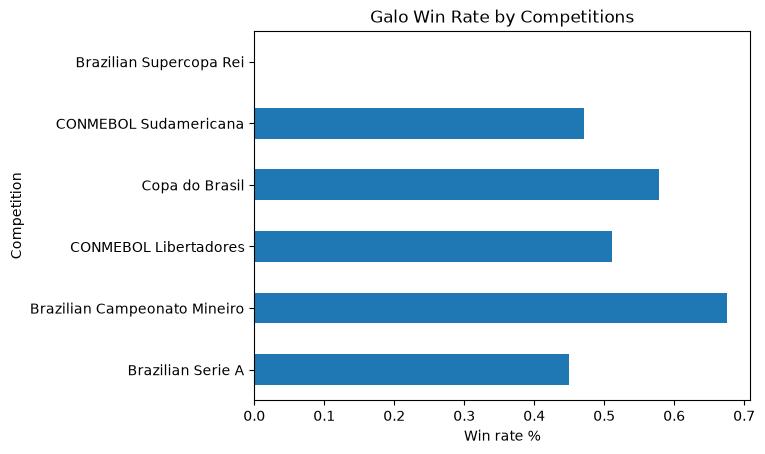

In [30]:
#Graph for overall winrate
comp_summary['win_rate'].plot(
    kind='barh',
    title = 'Galo Win Rate by Competitions'
)
plt.xlabel('Win rate %')
plt.show()

In [48]:
#Graph for wins, losses and draws
comp_pct = (
    df.groupby('Competition')['WinLossDraw'].value_counts(normalize=True).unstack().fillna(0))

comp_pct.head()

WinLossDraw,Draw,Loss,Win
Competition,,,
Brazilian Campeonato Mineiro,0.212500,0.112500,0.675000
Brazilian Serie A,0.273128,0.277533,0.449339
Brazilian Supercopa Rei,1.000000,0.000000,0.000000
CONMEBOL Libertadores,0.340426,0.148936,0.510638
CONMEBOL Sudamericana,0.352941,0.176471,0.470588


In [49]:
#Reorder columns logically
comp_pct = comp_pct[['Win', 'Draw', 'Loss']]

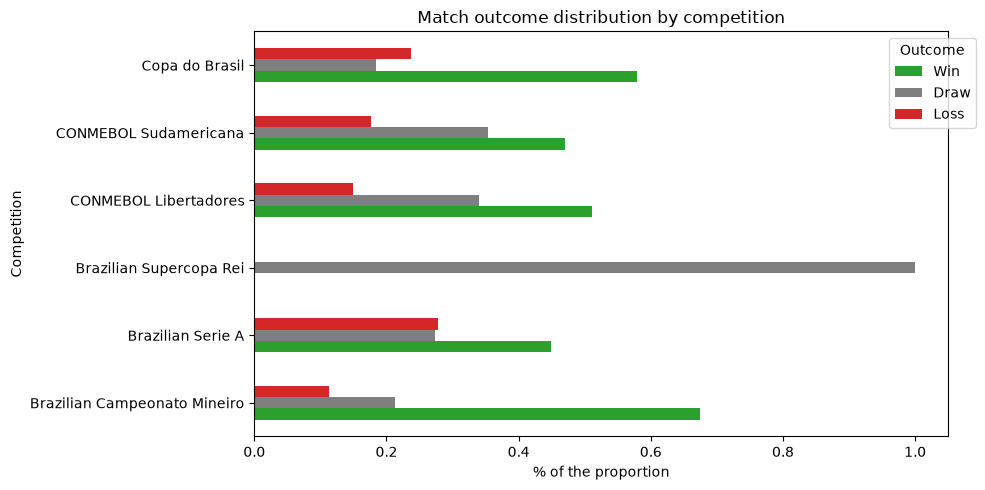

In [64]:
comp_pct.plot(
    kind='barh',
    figsize=(10,5),
    stacked=False,
    color=['#2ca02c', '#7f7f7f', '#d62728']
)
plt.title('Match outcome distribution by competition')
plt.xlabel('% of the proportion')
plt.legend(title='Outcome', bbox_to_anchor=(1.05,1))
plt.tight_layout()
plt.show()